# Week 9: Matching by design — similarity, propensity scores, and weighting


| Exercise | Question | Tool |
|---|---|---|
| 1 | Why is matching on many confounders hard, and what can one number do? | Propensity score |
| 2 | What should "similar" mean when covariates have scales and correlations? | Mahalanobis distance |

**Notation**

- $T$: treatment (1 = treated). *The slides wrote $X$ for treatment; here $X$ is a treated unit we want to match.*
- $Z$: observed confounders; $e(Z) = P(T = 1 \mid Z)$: propensity score
- $C$: a candidate control; $r$: a signed regression residual

Colors: **orange = treated**, **blue = untreated**.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.precision", 3)
TREAT, CTRL, GREY, INK = "#D9822B", "#1B5AA6", "#999999", "#333333"
TYPE_COLORS = {"A": "#7A5195", "B": "#5BA3A0", "High": "#7A5195", "Low": "#5BA3A0"}

---
## Exercise 1: Too many confounders → one number (12–15 min)

### A. The curse of dimensionality

- One **target** student and 1,000 **candidate** controls
- Each has $k$ confounders, all independent standard normal
- Distance between target and candidate: ordinary Euclidean distance over all $k$ confounders

**Discussion:** we'll add confounders one batch at a time.

- As $k$ grows, do distances get larger or smaller?
- Does the **nearest** candidate stay much closer than a **typical** one?
- What would that mean for finding a good match?

<div style="background:#FFF4E0; border-left:8px solid #D9822B; padding:12px 16px; margin:8px 0; font-size:1.25em;">
🔁 <b style="color:#D9822B;">WHAT-IF EXPERIMENT</b> &nbsp;—&nbsp; change <code>n_confounders</code>: try 5, 10, 25, 50, 100
</div>

In [2]:
# WHAT-IF EXPERIMENT
n_confounders = 2          # dimensions of each data point.
n_candidates = 1000


def distance_summary(k, n_candidates=1000, seed=0):
    rng = np.random.default_rng(seed)
    target = rng.normal(size=k)
    candidates = rng.normal(size=(n_candidates, k))
    d = np.sqrt(((candidates - target)**2).sum(axis=1))
    return {"confounders": k, "nearest": d.min(), "mean": d.mean(), "farthest": d.max(),
            "relative spread": (d.max() - d.min()) / d.min()}


pd.DataFrame([distance_summary(n_confounders, n_candidates) for n_confounders in [2,10,100,200]])

,confounders,nearest,mean,farthest,relative spread
0,2,0.110,1.265,4.069,36.122
1,10,1.078,3.896,6.349,4.890
2,100,11.413,13.869,16.573,0.452
3,200,17.125,19.596,22.743,0.328


- **Relative spread** $= (\text{farthest} - \text{nearest}) / \text{nearest}$: how much better the best candidate is than the worst

Now all values of $k$ at once:

**Another way to see it.** Suppose a candidate is "close enough" on any one confounder with probability $p$, independently across confounders. Then

$$P(\text{close enough on all } k) = p^k$$

In [3]:
p, k = 0.5, 10
print(f"p = {p}, k = {k}:  p**k = {p**k:.4f}  →  about 1 candidate in {1 / p**k:,.0f}")

p = 0.5, k = 10:  p**k = 0.0010  →  about 1 candidate in 1,024


<div style="background:#FFF4E0; border-left:8px solid #D9822B; padding:12px 16px; margin:8px 0; font-size:1.25em;">
🔁 <b style="color:#D9822B;">WHAT-IF EXPERIMENT</b> &nbsp;—&nbsp; change the treated counts: try A = 90, B = 50
</div>

In [4]:
# WHAT-IF EXPERIMENT: number treated out of 100 in each type
treated_counts = {"A": 70, "B": 70}       # try {"A": 90, "B": 50}

table = pd.DataFrame({"treated": treated_counts}).rename_axis("type")
table["untreated"] = 100 - table["treated"]
table["P(T=1 | type)"] = table["treated"] / 100
table

,treated,untreated,P(T=1 | type)
type,,,
A,70,30,0.7
B,70,30,0.7


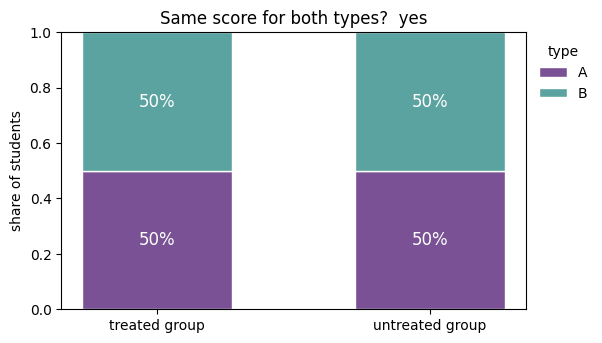

In [5]:
def plot_composition(table, title, value_label="students"):
    """Stacked bars: type mix of the treated group and of the untreated group."""
    shares = table[["treated", "untreated"]] / table[["treated", "untreated"]].sum()
    fig, ax = plt.subplots(figsize=(6, 3.6))
    bottom = np.zeros(2)
    for typ in shares.index:
        ax.bar(["treated group", "untreated group"], shares.loc[typ], bottom=bottom,
               color=TYPE_COLORS[typ], edgecolor="white", width=0.55, label=typ)
        for x, (b, h) in enumerate(zip(bottom, shares.loc[typ])):
            ax.text(x, b + h / 2, f"{h:.0%}", ha="center", va="center", color="white", fontsize=12)
        bottom += shares.loc[typ].values
    ax.set_ylabel(f"share of {value_label}")
    ax.set_ylim(0, 1)
    ax.set_title(title)
    ax.legend(frameon=False, bbox_to_anchor=(1, 1), loc="upper left", title=table.index.name)
    plt.show()


same_score = table["P(T=1 | type)"].nunique() == 1
plot_composition(table, "Same score for both types?  " + ("yes" if same_score else "NO"))

**Takeaway**

- Unbalancing the groups (e.g. 90 vs 50 treated) forces the treatment rates apart: $P(T=1 \mid A) = 0.9$, $P(T=1 \mid B) = 0.5$
- So the two types no longer share a propensity score
- Same **true** score ⇒ the type mix is the same in the treated and untreated groups

**But that's about probabilities, not counts.** In a real sample, chance alone moves the counts:

In [6]:
rng = np.random.default_rng(1)
draws = pd.DataFrame([{"sample": s,
                       "A treated": rng.binomial(100, 0.7),
                       "B treated": rng.binomial(100, 0.7)} for s in range(1, 6)]).set_index("sample")
draws

,A treated,B treated
sample,,
1,74,67
2,79,71
3,69,67
4,70,68
5,65,73


- Same true score (0.7) for everyone, yet the realized counts differ by a few students
- Balance holds in the **population**; a finite sample is only approximately balanced

**Closing question:** in real data we **estimate** $e(Z)$. Does matching on an estimated score guarantee perfect balance in our sample?

- No: the balancing property is about the true score; estimation error and finite samples leave imbalance → check balance after matching

---
## Exercise 2: Building Mahalanobis distance from intuition (12–15 min)

### A. Two correlated confounders on different scales

- **GPA** (around 3.0, SD 0.4) and **test score** (around 1200, SD 150)
- They move together: correlation $\rho$
- One treated student $X$ and four candidate controls $C_1, \dots, C_4$; grey dots are the rest of the student population

<div style="background:#FFF4E0; border-left:8px solid #D9822B; padding:12px 16px; margin:8px 0; font-size:1.25em;">
🔁 <b style="color:#D9822B;">WHAT-IF EXPERIMENT</b> &nbsp;—&nbsp; later, change <code>rho</code> (try 0.3 or 0.95) and rerun Exercise 2
</div>

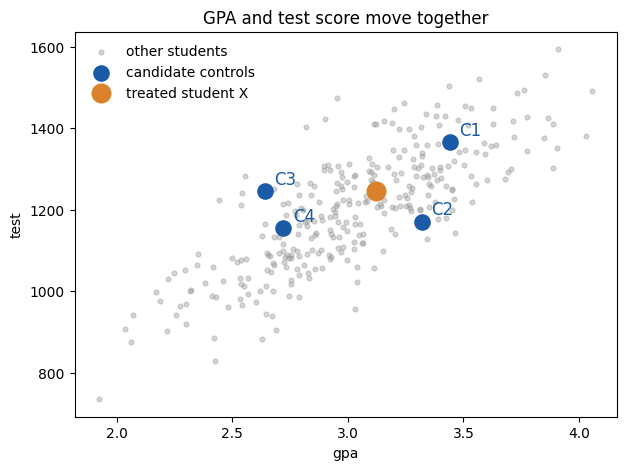

In [7]:
# WHAT-IF EXPERIMENT
rho = 0.8                   # correlation between GPA and test score; try 0.3, 0.95

MEAN = np.array([3.0, 1200])
SD = np.array([0.4, 150])
rng = np.random.default_rng(2)
z_std = rng.multivariate_normal([0, 0], [[1, rho], [rho, 1]], size=300)
population = pd.DataFrame(MEAN + z_std * SD, columns=["gpa", "test"])

# focal treated student X and four candidates, placed in standardized units for a clear story
offsets = {"C1": (0.8, 0.8), "C2": (0.5, -0.5), "C3": (-1.2, 0.0), "C4": (-1.0, -0.6)}
x_std = np.array([0.3, 0.3])
focal = pd.DataFrame({name: MEAN + (x_std + np.array(off)) * SD for name, off in offsets.items()},
                     index=["gpa", "test"]).T
X = pd.Series(MEAN + x_std * SD, index=["gpa", "test"], name="X")


def plot_students(data, cands, target, x="gpa", y="test", title="", line=None, arrows=()):
    fig, ax = plt.subplots(figsize=(7, 5))
    ax.scatter(data[x], data[y], s=12, color=GREY, alpha=0.4, label="other students")
    ax.scatter(cands[x], cands[y], s=120, color=CTRL, zorder=3, label="candidate controls")
    for name, row in cands.iterrows():
        ax.annotate(name, (row[x], row[y]), xytext=(7, 5), textcoords="offset points", color=CTRL, fontsize=12)
    ax.scatter(target[x], target[y], s=180, color=TREAT, zorder=4, label="treated student X")
    if line is not None:
        xs = np.linspace(data[x].min(), data[x].max(), 50)
        ax.plot(xs, line[0] + line[1] * xs, color=INK, lw=2, label="regression line")
    for name in arrows:
        ax.annotate("", xy=(cands.loc[name, x], cands.loc[name, y]), xytext=(target[x], target[y]),
                    arrowprops=dict(arrowstyle="-|>", color=TREAT, lw=2), zorder=5)
    ax.set_xlabel(x)
    ax.set_ylabel(y)
    ax.set_title(title)
    ax.legend(frameon=False, loc="upper left", fontsize=10)
    plt.show()


plot_students(population, focal, X, title="GPA and test score move together")

### B. Start with Euclidean distance

$$d_E(X, C) = \sqrt{(Z_{1,X} - Z_{1,C})^2 + (Z_{2,X} - Z_{2,C})^2}$$

<div style="background:#FFF4E0; border-left:8px solid #D9822B; padding:12px 16px; margin:8px 0; font-size:1.25em;">
⌨️ <b style="color:#D9822B;">LIVE CODING</b> &nbsp;—&nbsp; write the Euclidean distance; which candidate is nearest?
</div>

In [8]:
# LIVE CODING
def euclidean(a, b):
    return np.sqrt(((a - b)**2).sum())


distances = pd.DataFrame({"raw Euclidean": {c: euclidean(X.values, focal.loc[c].values) for c in focal.index}})
distances.join(focal)

,raw Euclidean,gpa,test
C1,120.000,3.44,1365.0
C2,75.000,3.32,1170.0
C3,0.480,2.64,1245.0
C4,90.001,2.72,1155.0


**Discussion:**

- Which candidate wins, and why? Look at its GPA.
- What's wrong with adding a GPA gap to a test-score gap?

### C. Account for scale

Put every confounder in SD units first:

$$Z_j^* = \frac{Z_j - \mu_j}{\sigma_j}$$

In [9]:
mu, sigma = population.mean(), population.std(ddof=0)


def standardize(df):
    return (df - mu) / sigma


pop_s, focal_s, X_s = standardize(population), standardize(focal), standardize(X)
distances["standardized Euclidean"] = {c: euclidean(X_s.values, focal_s.loc[c].values) for c in focal.index}
distances

,raw Euclidean,standardized Euclidean
C1,120.000,1.143
C2,75.000,0.715
C3,0.480,1.197
C4,90.001,1.171


- $C_3$ was only "near" because a whole GPA gap counted as almost nothing next to test points
- The winner changes. Is the new winner a good match?

### D. The correlation structure

Fit a line through the standardized population:

$$Z_2^* = \alpha + \beta Z_1^* + \varepsilon$$

In [10]:
import statsmodels.api as sm
# run pop_s[test] ~ pop_s[gpa]

model = sm.OLS(pop_s['test'],sm.add_constant(pop_s['gpa'])).fit()


model.params




const    1.596e-16
gpa      7.948e-01
dtype: float64

slope beta = 0.79  (with standardized data this equals the correlation)


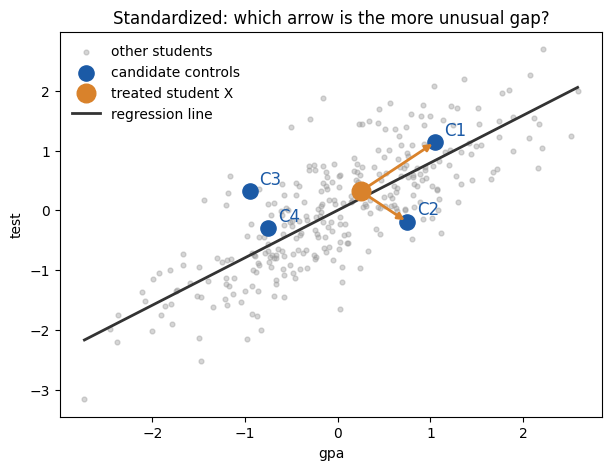

In [11]:
# feed in fit params from above


beta = model.params['gpa']
alpha = model.params['const']

print(f"slope beta = {beta:.2f}  (with standardized data this equals the correlation)")
plot_students(pop_s, focal_s, X_s, title="Standardized: which arrow is the more unusual gap?",
              line=(alpha, beta), arrows=("C1", "C2"))

**Discussion:** the arrows to $C_1$ and $C_2$ have similar lengths.

- Which gap is **typical** for this population: the one along the line, or the one across it?
- A student with high GPA **and** high test score is common. High GPA but low test score?
- So which candidate is more like $X$?

### E. A homemade correlation-aware distance

Idea: also compare how far each student sits **above or below the line**: their signed residual

$$r_i = Z_{2,i}^* - \widehat{Z}_{2,i}^*$$

- Compare residuals by their **difference** $|r_X - r_C|$: two students both well above the line are similar in this respect
- Being close to the line does **not** make a good match; deviating the same way as $X$ does

Mix the two pieces with a weight $\lambda$:

$$d_{\text{home}}(X, C) = \lambda\, d_E(X, C) + (1 - \lambda)\, |r_X - r_C|$$

- $\lambda = 1$: standardized Euclidean only; $\lambda = 0$: residual difference only

<div style="background:#FFF4E0; border-left:8px solid #D9822B; padding:12px 16px; margin:8px 0; font-size:1.25em;">
⌨️ <b style="color:#D9822B;">LIVE CODING</b> &nbsp;—&nbsp; compute residuals and the homemade distance &nbsp;|&nbsp; 🔁 then change <code>lambda_weight</code>
</div>

In [12]:
# pop_s, X_s, focal_s
# beta, alpha

# first score is based on euclidean_distances between X_s and candidates
score1 = np.array([euclidean(X_s, c) for c in focal_s.to_numpy()])


# second score is |rx - rc|.
# rx: residual for Xs
# rc: residual for candidate

# how far X is from regression line (residual)
rx = X_s['test'] - (beta * X_s['gpa'] + alpha)

# how far residual is from the regression line
rc = focal_s['test'] - (beta * focal_s['gpa'] + alpha)

# convert into numpy at the end
score2 = np.abs(rx - rc).to_numpy()

# how we weight the two scores
# lmda = 1 means just focus on euclidean distance
# lmda = 0 means just focus on |rx-rc|

lmda = 0.5

# our homemade score balances euclidean distance and difference in residuals (from the regression line)
score = lmda * score1 + (1.0-lmda) * score2

# creating a copy instead of overwriting focal_s
cands = focal_s.copy()
cands['homemade_score'] = score

cands












,gpa,test,homemade_score
C1,1.047,1.137,0.664
C2,0.748,-0.193,0.811
C3,-0.948,0.319,1.074
C4,-0.748,-0.295,0.675


In [13]:
# LIVE CODING
def residual(df_s):
    return df_s["test"] - (alpha + beta * df_s["gpa"])


r_X = residual(X_s)
r_focal = residual(focal_s)

# WHAT-IF EXPERIMENT
lambda_weight = 0.5      # try 1.0, 0.5, 0.2, 0.0

parts = pd.DataFrame({"d_E": distances["standardized Euclidean"], "|r_X - r_C|": (r_X - r_focal).abs()})
distances["homemade"] = lambda_weight * parts["d_E"] + (1 - lambda_weight) * parts["|r_X - r_C|"]
parts.join(distances["homemade"])

,d_E,|r_X - r_C|,homemade
C1,1.143,0.185,0.664
C2,0.715,0.908,0.811
C3,1.197,0.951,1.074
C4,1.171,0.179,0.675


- Check the two columns' sizes: residual gaps tend to be **smaller** than $d_E$ (residuals only vary by about $\sqrt{1-\rho^2}$ SD). Keep that in mind when choosing $\lambda$; we'll return to it.

### F. The established method: Mahalanobis distance

$$d_M(X, C) = \sqrt{(X - C)^T\, \Sigma^{-1} (X - C)}$$

- $\Sigma$: the covariance matrix of the confounders → accounts for **scale and correlation** in one step
- Works on the raw data directly: it standardizes for you

In [14]:
Sigma = np.cov(population.T.values, ddof=0)
Sigma_inv = np.linalg.inv(Sigma)


def mahalanobis(a, b):
    diff = a - b
    return np.sqrt(diff @ Sigma_inv @ diff)


distances["Mahalanobis"] = {c: mahalanobis(X.values, focal.loc[c].values) for c in focal.index}
ranks = distances.rank().astype(int)
print("Nearest candidate by each distance:")
print(distances.idxmin().to_string())
ranks

Nearest candidate by each distance:
raw Euclidean             C3
standardized Euclidean    C2
homemade                  C1
Mahalanobis               C1


,raw Euclidean,standardized Euclidean,homemade,Mahalanobis
C1,4,2,1,1
C2,2,1,3,3
C3,1,4,4,4
C4,3,3,2,2


**Discussion:**

- Raw, standardized, and Mahalanobis distances each pick a different nearest candidate. Why?
- Which $\lambda$ made the homemade distance agree with Mahalanobis?

**Sweep $\lambda$ for our focal student**

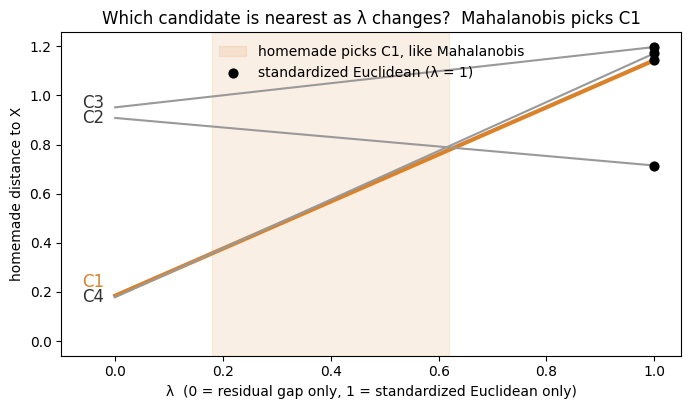

In [15]:
lambdas = np.linspace(0, 1, 101)
home = {c: lambdas * parts.loc[c, "d_E"] + (1 - lambdas) * parts.loc[c, "|r_X - r_C|"] for c in focal.index}
m_pick = distances["Mahalanobis"].idxmin()
agrees = np.array([min(home, key=lambda c: home[c][i]) == m_pick for i in range(len(lambdas))])

fig, ax = plt.subplots(figsize=(8, 4.2))
ax.fill_between(lambdas, 0, 1, where=agrees, transform=ax.get_xaxis_transform(), color=TREAT, alpha=0.12,
                label=f"homemade picks {m_pick}, like Mahalanobis")
label_y = {}
for c in sorted(focal.index, key=lambda c: home[c][0]):        # nudge labels so they don't overlap
    prev = max(label_y.values(), default=-np.inf)
    label_y[c] = max(home[c][0], prev + 0.06)
for c in focal.index:
    ax.plot(lambdas, home[c], color=TREAT if c == m_pick else GREY, lw=3 if c == m_pick else 1.5)
    ax.text(-0.02, label_y[c], c, ha="right", va="center", color=TREAT if c == m_pick else INK, fontsize=12)
ax.scatter([1] * len(focal), parts["d_E"], color="black", zorder=4, s=40, label="standardized Euclidean (λ = 1)")
ax.set_xlim(-0.1, 1.05)
ax.set_xlabel("λ  (0 = residual gap only, 1 = standardized Euclidean only)")
ax.set_ylabel("homemade distance to X")
ax.set_title(f"Which candidate is nearest as λ changes?  Mahalanobis picks {m_pick}")
ax.legend(frameon=False, loc="upper center", fontsize=10)
plt.show()